# Machine Learning Assignment 2 — Question 3
## Bias and variance as measured quantities

Run all cells top-to-bottom in Google Colab/Jupyter. This notebook measures the bias-squared and variance quantities defined in the assignment using 30 resampled training sets, while keeping the original test set fixed.

**Setup**
- Roll number: `m24ma2007`; seed: `242007`
- Olivetti Faces, raw flattened 4,096 pixel features; no PCA or other dimensionality reduction
- Fixed 6 train / 2 validation / 2 test images per identity
- 30 bootstrap refits, sampled with replacement *within each identity* from that identity's original six training faces
- Models are trained only on clean images; the masked test set is for evaluation only.

This notebook uses actual measured results from execution. It does not hard-code performance numbers. Keep the split and model configurations aligned with Q1 and Q2 outputs.

## 0. Imports and configuration

In [1]:
# If needed in a fresh environment:
# %pip install -q numpy pandas matplotlib scikit-learn

import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from IPython.display import display

ROLL_NUMBER = "m24ma2007"
SEED = int("".join(ch for ch in ROLL_NUMBER if ch.isdigit()))
assert SEED == 242007
N_REPEATS = 30
OUT_DIR = "q3_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print("Seed:", SEED, "| repeats:", N_REPEATS, "| output:", os.path.abspath(OUT_DIR))

Seed: 242007 | repeats: 30 | output: /home/M24MA2009/pawanassign/q3_outputs


## 1. Load the data and fixed split

Load the saved Q1 split if available. If it is not in the current Colab session, reproduce it deterministically using the same seed and per-identity split procedure, then save it. The test set remains fixed throughout all 30 refits.

In [2]:
faces = fetch_olivetti_faces(shuffle=False)
X_images = faces.images.astype(np.float32)
y = faces.target.astype(np.int64)
X = X_images.reshape(len(X_images), -1)
assert X_images.shape == (400, 64, 64) and X.shape == (400, 4096)
assert len(np.unique(y)) == 40
assert all(np.sum(y == c) == 10 for c in np.unique(y))

split_candidates = [
    os.path.join("q1_outputs", "olivetti_split_seed_242007.npz"),
    os.path.join("q2_outputs", "olivetti_split_seed_242007.npz"),
    "olivetti_split_seed_242007.npz",
]
split_path = next((p for p in split_candidates if os.path.exists(p)), None)
if split_path:
    z = np.load(split_path, allow_pickle=False)
    train_idx, val_idx, test_idx = z["train_idx"].astype(int), z["val_idx"].astype(int), z["test_idx"].astype(int)
    print("Loaded saved split:", split_path)
else:
    split_rng = np.random.default_rng(SEED)
    train_idx, val_idx, test_idx = [], [], []
    for identity in sorted(np.unique(y)):
        ids = np.flatnonzero(y == identity)
        shuffled = split_rng.permutation(ids)
        train_idx.extend(shuffled[:6].tolist())
        val_idx.extend(shuffled[6:8].tolist())
        test_idx.extend(shuffled[8:10].tolist())
    train_idx, val_idx, test_idx = map(lambda a: np.asarray(a, dtype=np.int64),
                                       (train_idx, val_idx, test_idx))
    split_path = os.path.join(OUT_DIR, "olivetti_split_seed_242007.npz")
    np.savez_compressed(split_path, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx,
                        seed=np.asarray(SEED), roll_number=np.asarray(ROLL_NUMBER))
    print("Generated and saved identical deterministic split:", split_path)

assert (len(train_idx), len(val_idx), len(test_idx)) == (240, 80, 80)
assert not (set(train_idx) & set(val_idx))
assert not (set(train_idx) & set(test_idx))
assert not (set(val_idx) & set(test_idx))
for identity in np.unique(y):
    assert np.sum(y[train_idx] == identity) == 6
    assert np.sum(y[val_idx] == identity) == 2
    assert np.sum(y[test_idx] == identity) == 2

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]
X_images_masked = X_images.copy()
X_images_masked[:, 24:40, 24:40] = 0.0
X_masked = X_images_masked.reshape(400, -1)
X_test_masked = X_masked[test_idx]
classes = np.unique(y_train)
K = len(classes)
print("Data shapes:", X_train.shape, X_val.shape, X_test.shape, X_test_masked.shape)

Loaded saved split: q1_outputs/olivetti_split_seed_242007.npz
Data shapes: (240, 4096) (80, 4096) (80, 4096) (80, 4096)


## 2. Load or recreate the frozen Q1/Q2 model settings

The assignment says not to tune again during Q3. Prefer the settings saved by the Q1 and Q2 notebooks. If those output files are not present, this notebook asks you to enter the frozen settings recorded from your runs; it does not silently tune using the test set.

In [4]:


if MANUAL_TREE_DEPTH is not None or MANUAL_TREE_MIN_LEAF is not None:
    if MANUAL_TREE_MIN_LEAF is None:
        raise ValueError(
            "Set MANUAL_TREE_MIN_LEAF as well as MANUAL_TREE_DEPTH."
        )
    TREE_DEPTH = MANUAL_TREE_DEPTH
    TREE_MIN_LEAF = int(MANUAL_TREE_MIN_LEAF)

elif q1_tree_path:
    r = pd.read_csv(q1_tree_path).iloc[0]

    # Handle None, NaN, blank values, and numeric depths safely.
    depth_value = r["selected_max_depth"]

    if pd.isna(depth_value) or str(depth_value).strip().lower() in {
        "none", "nan", ""
    }:
        TREE_DEPTH = None
    else:
        TREE_DEPTH = int(float(depth_value))

    leaf_value = r["selected_min_samples_leaf"]
    if pd.isna(leaf_value):
        raise ValueError(
            "selected_min_samples_leaf is missing in the Q1 CSV. "
            "Check q1a_selected_tree_metrics.csv."
        )
    TREE_MIN_LEAF = int(float(leaf_value))

else:
    raise FileNotFoundError(
        "Frozen Q1 tree setting not found. "
        "Set MANUAL_TREE_DEPTH and MANUAL_TREE_MIN_LEAF above."
    )


# Select the final bagging size.
if MANUAL_FINAL_B is not None:
    FINAL_B = int(MANUAL_FINAL_B)

elif q1_bag_path:
    q1bag = pd.read_csv(q1_bag_path)
    valid_bag = q1bag.dropna(
        subset=["validation_accuracy", "B"]
    )

    if valid_bag.empty:
        raise ValueError(
            "No valid validation results found in the Q1 bagging CSV."
        )

    best = valid_bag["validation_accuracy"].max()
    FINAL_B = int(
        valid_bag.loc[
            valid_bag["validation_accuracy"] == best, "B"
        ].min()
    )

else:
    raise FileNotFoundError(
        "Frozen Q1 final bagging size not found. "
        "Set MANUAL_FINAL_B above."
    )


# Select the boosting configuration.
if (
    MANUAL_BOOST_DEPTH is not None
    and MANUAL_BOOST_ROUNDS is not None
):
    BOOST_DEPTH = int(MANUAL_BOOST_DEPTH)
    BOOST_ROUNDS = int(MANUAL_BOOST_ROUNDS)

elif q2_grid_path:
    q2grid = pd.read_csv(q2_grid_path)

    valid_grid = q2grid.dropna(
        subset=[
            "validation_accuracy",
            "requested_rounds",
            "max_depth",
        ]
    )

    if valid_grid.empty:
        raise ValueError(
            "No valid boosting results found in the Q2 validation CSV."
        )

    ranked = valid_grid.sort_values(
        ["validation_accuracy", "requested_rounds", "max_depth"],
        ascending=[False, True, True],
        kind="stable",
    )

    selected = ranked.iloc[0]
    BOOST_DEPTH = int(selected["max_depth"])
    BOOST_ROUNDS = int(selected["requested_rounds"])

else:
    raise FileNotFoundError(
        "Frozen Q2 boosting setting not found. "
        "Set MANUAL_BOOST_DEPTH and MANUAL_BOOST_ROUNDS above."
    )


print("Frozen settings:", {
    "tree_depth": TREE_DEPTH,
    "tree_min_samples_leaf": TREE_MIN_LEAF,
    "bagging_B": FINAL_B,
    "boosting_depth": BOOST_DEPTH,
    "boosting_requested_rounds": BOOST_ROUNDS,
})


Frozen settings: {'tree_depth': None, 'tree_min_samples_leaf': 1, 'bagging_B': 200, 'boosting_depth': 4, 'boosting_requested_rounds': 100}


## 3. Define scratch SAMME and probability/vote outputs

For Q3, use the same SAMME update rule and normalised weighted vote vector as Q2. The score vector for each sample is divided by the sum of learner weights, as specified in the assignment. This makes each model's output a class vector for bias/variance calculations.

In [5]:
class ScratchSAMME:
    def __init__(self, max_depth=1, n_estimators=50, random_state=0):
        self.max_depth = max_depth
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.estimators_ = []
        self.estimator_weights_ = []
        self.classes_ = None
        self.stop_reason_ = None

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        self.classes_ = np.unique(y)
        K = len(self.classes_)
        w = np.full(len(y), 1.0 / len(y), dtype=float)
        self.estimators_, self.estimator_weights_ = [], []
        self.stop_reason_ = "requested_rounds_reached"
        eps = np.finfo(float).eps
        for t in range(self.n_estimators):
            est = DecisionTreeClassifier(max_depth=self.max_depth, random_state=self.random_state + t)
            est.fit(X, y, sample_weight=w)
            pred = est.predict(X)
            miss = pred != y
            err = float(np.sum(w * miss))
            if err >= 1.0 - 1.0 / K:
                self.stop_reason_ = "weak_learner_not_better_than_random"
                break
            perfect = err <= eps
            e = max(err, eps)
            alpha = float(np.log((1.0 - e) / e) + np.log(K - 1))
            self.estimators_.append(est)
            self.estimator_weights_.append(alpha)
            if not perfect:
                w *= np.exp(alpha * miss.astype(float))
                w /= w.sum()
            if perfect:
                self.stop_reason_ = "perfect_learner"
                break
        return self

    def predict_proba(self, X):
        if not self.estimators_:
            raise RuntimeError("No accepted SAMME learners.")
        scores = np.zeros((len(X), len(self.classes_)), dtype=float)
        class_to_col = {c: i for i, c in enumerate(self.classes_)}
        for est, alpha in zip(self.estimators_, self.estimator_weights_):
            p = est.predict(X)
            for c in np.unique(p):
                scores[p == c, class_to_col[c]] += alpha
        total = sum(self.estimator_weights_)
        return scores / total if total > 0 else np.full_like(scores, 1.0 / len(self.classes_))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

def class_vectors_from_tree(tree_model, X_eval, classes):
    raw = tree_model.predict_proba(X_eval)
    aligned = np.zeros((len(X_eval), len(classes)), dtype=float)
    class_to_col = {c: i for i, c in enumerate(classes)}
    for j, c in enumerate(tree_model.classes_):
        aligned[:, class_to_col[c]] = raw[:, j]
    return aligned

def class_vectors_from_bagging(models, X_eval, classes):
    votes = np.zeros((len(X_eval), len(classes)), dtype=float)
    class_to_col = {c: i for i, c in enumerate(classes)}
    for model in models:
        pred = model.predict(X_eval)
        for c in np.unique(pred):
            votes[pred == c, class_to_col[c]] += 1.0
    return votes / len(models)

print("SAMME implementation ready.")

SAMME implementation ready.


## 4. Fit selected models on the original training set and validate configuration

These are the frozen models whose configurations were selected in Q1 and Q2. No hyperparameter selection is performed using test data.

In [6]:
single_tree = DecisionTreeClassifier(
    max_depth=TREE_DEPTH, min_samples_leaf=TREE_MIN_LEAF, random_state=SEED
).fit(X_train, y_train)

# Reproducible bagging sequence, same procedure as Q1.
bag_rng = np.random.default_rng(SEED + 1)
bag_models_all = []
for b in range(FINAL_B):
    boot_idx = bag_rng.integers(0, len(X_train), size=len(X_train))
    est = DecisionTreeClassifier(
        max_depth=TREE_DEPTH, min_samples_leaf=TREE_MIN_LEAF,
        random_state=SEED + 1000 + b
    )
    est.fit(X_train[boot_idx], y_train[boot_idx])
    bag_models_all.append(est)

boost_model = ScratchSAMME(
    max_depth=BOOST_DEPTH, n_estimators=BOOST_ROUNDS, random_state=SEED + 5000
).fit(X_train, y_train)

print("Actual boosting rounds:", len(boost_model.estimators_), "stop reason:", boost_model.stop_reason_)

Actual boosting rounds: 100 stop reason: requested_rounds_reached


## 5. Q3(a): bias squared and variance for selected models

The assignment defines, for each fixed test image \(x_i\), the mean class vector \(\bar p(x_i)\) across the 30 refits and one-hot target vector \(e_i\). Compute

\[
\mathrm{Bias}^2=\frac{1}{N}\sum_i\|\bar p(x_i)-e_i\|_2^2,
\quad
\mathrm{Variance}=\frac{1}{NR}\sum_i\sum_r\|p_r(x_i)-\bar p(x_i)\|_2^2.
\]

For tree and bagging models, use class-probability / normalised vote vectors. For boosting, use the assignment's normalised weighted vote vector. Every refit uses a new within-identity bootstrap training set sampled from each identity's original six training images. The fixed clean test set is never resampled.

In [7]:
def make_stratified_bootstrap_train_indices(rng):
    # Sample six training positions with replacement within each identity.
    # Return positions into X_train/y_train, preserving 6 samples per identity.
    sampled_positions = []
    for identity in sorted(np.unique(y_train)):
        positions = np.flatnonzero(y_train == identity)
        draw = rng.choice(positions, size=6, replace=True)
        sampled_positions.extend(draw.tolist())
    return np.asarray(sampled_positions, dtype=int)

def fit_predict_vectors_for_repetition(rep, X_eval):
    rng = np.random.default_rng(SEED + 20000 + rep)
    sampled = make_stratified_bootstrap_train_indices(rng)
    Xr, yr = X_train[sampled], y_train[sampled]

    # Refit the selected single tree with frozen hyperparameters.
    tree_r = DecisionTreeClassifier(
        max_depth=TREE_DEPTH, min_samples_leaf=TREE_MIN_LEAF,
        random_state=SEED + 30000 + rep
    ).fit(Xr, yr)
    p_tree = class_vectors_from_tree(tree_r, X_eval, classes)

    # Refit selected bagged model on the resampled set: each member bootstraps
    # from this resampled training set, with the same frozen tree setting.
    brng = np.random.default_rng(SEED + 40000 + rep)
    bag_r = []
    for b in range(FINAL_B):
        boot = brng.integers(0, len(Xr), size=len(Xr))
        est = DecisionTreeClassifier(
            max_depth=TREE_DEPTH, min_samples_leaf=TREE_MIN_LEAF,
            random_state=SEED + 50000 + rep * 1000 + b
        ).fit(Xr[boot], yr[boot])
        bag_r.append(est)
    p_bag = class_vectors_from_bagging(bag_r, X_eval, classes)

    # Refit selected SAMME model with frozen depth and requested rounds.
    boost_r = ScratchSAMME(
        max_depth=BOOST_DEPTH, n_estimators=BOOST_ROUNDS,
        random_state=SEED + 60000 + rep * 1000
    ).fit(Xr, yr)
    p_boost = boost_r.predict_proba(X_eval)

    return {
        "Single tree": (p_tree, tree_r),
        "Bagging": (p_bag, bag_r),
        "Boosting": (p_boost, boost_r)
    }

def bias_variance_from_vectors(P, y_true, classes):
    # P shape: repetitions x examples x classes.
    mean_p = P.mean(axis=0)
    class_to_col = {c: i for i, c in enumerate(classes)}
    target = np.zeros((len(y_true), len(classes)), dtype=float)
    for i, c in enumerate(y_true):
        target[i, class_to_col[c]] = 1.0
    bias2 = float(np.mean(np.sum((mean_p - target) ** 2, axis=1)))
    variance = float(np.mean(np.sum((P - mean_p[None, :, :]) ** 2, axis=2)))
    return bias2, variance, mean_p

# Keep fixed test images and collect all repetitions.
all_vectors = {"Single tree": [], "Bagging": [], "Boosting": []}
rep_accuracy_rows = []
start_all = time.perf_counter()
for rep in range(N_REPEATS):
    pred_map = fit_predict_vectors_for_repetition(rep, X_test)
    for name, (vec, fitted) in pred_map.items():
        all_vectors[name].append(vec)
        pred = classes[np.argmax(vec, axis=1)]
        rep_accuracy_rows.append({
            "repetition": rep + 1,
            "model": name,
            "test_accuracy": float(accuracy_score(y_test, pred))
        })
    if (rep + 1) % 5 == 0:
        print(f"Completed {rep+1}/{N_REPEATS} refits; elapsed {time.perf_counter()-start_all:.1f}s")

P = {name: np.stack(vectors, axis=0) for name, vectors in all_vectors.items()}
rep_accuracy = pd.DataFrame(rep_accuracy_rows)
rep_accuracy.to_csv(os.path.join(OUT_DIR, "q3a_test_accuracy_by_refit.csv"), index=False)

q3a_rows = []
for name, vectors in P.items():
    bias2, variance, mean_p = bias_variance_from_vectors(vectors, y_test, classes)
    accs = rep_accuracy.loc[rep_accuracy["model"] == name, "test_accuracy"].to_numpy()
    q3a_rows.append({
        "model": name,
        "bias_squared": bias2,
        "variance": variance,
        "mean_test_accuracy": float(np.mean(accs)),
        "std_test_accuracy": float(np.std(accs, ddof=1))
    })
q3a_df = pd.DataFrame(q3a_rows)
display(q3a_df)
q3a_df.to_csv(os.path.join(OUT_DIR, "q3a_bias_variance_selected_models.csv"), index=False)

Completed 5/30 refits; elapsed 1478.8s
Completed 10/30 refits; elapsed 2895.7s
Completed 15/30 refits; elapsed 4394.8s
Completed 20/30 refits; elapsed 5921.6s
Completed 25/30 refits; elapsed 7492.6s
Completed 30/30 refits; elapsed 8888.1s


,model,bias_squared,variance,mean_test_accuracy,std_test_accuracy
0,Single tree,0.353000,0.617833,0.514583,0.047806
1,Bagging,0.491176,0.018820,0.817500,0.037370
2,Boosting,0.885714,0.016619,0.315417,0.070839


## 6. Q3(b): compare shallow, selected, and deep single trees and 100-tree bagging

Use one shallow depth, the selected depth, and one much deeper depth. The defaults below choose the shallowest allowed depth 2, the frozen selected depth, and depth `None` (unrestricted). The single tree and 100-tree bagging ensemble are refit on each of the same 30 within-identity resampled training sets. Do not tune these choices against the test set.

In [8]:
DEPTH_COMPARISON = [
    ("shallow_depth_2", 2),
    ("selected_depth", TREE_DEPTH),
    ("deep_depth_None", None)
]
DEPTH_COMPARISON

[('shallow_depth_2', 2), ('selected_depth', None), ('deep_depth_None', None)]

In [9]:
def fit_tree_and_bag_vectors_for_depth(rep, depth, X_eval, n_bag=100):
    rng = np.random.default_rng(SEED + 20000 + rep)
    sampled = make_stratified_bootstrap_train_indices(rng)
    Xr, yr = X_train[sampled], y_train[sampled]

    tr = DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=TREE_MIN_LEAF,
        random_state=SEED + 70000 + rep
    ).fit(Xr, yr)
    p_tree = class_vectors_from_tree(tr, X_eval, classes)

    brng = np.random.default_rng(SEED + 80000 + rep)
    bag = []
    for b in range(n_bag):
        boot = brng.integers(0, len(Xr), size=len(Xr))
        est = DecisionTreeClassifier(
            max_depth=depth, min_samples_leaf=TREE_MIN_LEAF,
            random_state=SEED + 90000 + rep * 1000 + b
        ).fit(Xr[boot], yr[boot])
        bag.append(est)
    p_bag = class_vectors_from_bagging(bag, X_eval, classes)
    return p_tree, p_bag, tr, bag

depth_vectors = {}
depth_accuracy_rows = []
depth_leaf_rows = []
start_depths = time.perf_counter()

for label, depth in DEPTH_COMPARISON:
    depth_vectors[label] = {"Single tree": [], "Bagging-100": []}
    for rep in range(N_REPEATS):
        p_tree, p_bag, tr, bag = fit_tree_and_bag_vectors_for_depth(rep, depth, X_test, n_bag=100)
        depth_vectors[label]["Single tree"].append(p_tree)
        depth_vectors[label]["Bagging-100"].append(p_bag)

        pred_tree = classes[np.argmax(p_tree, axis=1)]
        pred_bag = classes[np.argmax(p_bag, axis=1)]
        depth_accuracy_rows.extend([
            {"depth_setting": label, "depth": str(depth), "repetition": rep+1,
             "model": "Single tree", "test_accuracy": accuracy_score(y_test, pred_tree)},
            {"depth_setting": label, "depth": str(depth), "repetition": rep+1,
             "model": "Bagging-100", "test_accuracy": accuracy_score(y_test, pred_bag)}
        ])
        if rep == 0:
            leaf_ids = tr.apply(Xr) if "Xr" in locals() else None
            # Record leaf count and occupancy from this fitted tree on its resampled fit data.
            depth_leaf_rows.append({
                "depth_setting": label, "depth": str(depth),
                "tree_leaf_count": int(tr.get_n_leaves()),
                "tree_max_depth_observed": int(tr.get_depth())
            })
    print(f"Completed depth setting {label}; elapsed {time.perf_counter()-start_depths:.1f}s")

depth_accuracy = pd.DataFrame(depth_accuracy_rows)
depth_accuracy.to_csv(os.path.join(OUT_DIR, "q3b_depth_test_accuracy_by_refit.csv"), index=False)
depth_leaf_df = pd.DataFrame(depth_leaf_rows)
depth_leaf_df.to_csv(os.path.join(OUT_DIR, "q3b_leaf_statistics.csv"), index=False)

q3b_rows = []
for label, depth in DEPTH_COMPARISON:
    for model_name, vector_list in depth_vectors[label].items():
        vectors = np.stack(vector_list, axis=0)
        bias2, variance, _ = bias_variance_from_vectors(vectors, y_test, classes)
        acc = depth_accuracy[(depth_accuracy["depth_setting"] == label) &
                             (depth_accuracy["model"] == model_name)]["test_accuracy"].to_numpy()
        q3b_rows.append({
            "depth_setting": label, "depth": str(depth), "model": model_name,
            "bias_squared": bias2, "variance": variance,
            "mean_test_accuracy": float(np.mean(acc)),
            "std_test_accuracy": float(np.std(acc, ddof=1))
        })
q3b_df = pd.DataFrame(q3b_rows)
display(q3b_df)
display(depth_leaf_df)
q3b_df.to_csv(os.path.join(OUT_DIR, "q3b_depth_bias_variance.csv"), index=False)

Completed depth setting shallow_depth_2; elapsed 439.0s
Completed depth setting selected_depth; elapsed 4172.0s
Completed depth setting deep_depth_None; elapsed 8201.5s


,depth_setting,depth,model,bias_squared,variance,mean_test_accuracy,std_test_accuracy
0,shallow_depth_2,2,Single tree,0.912198,0.045921,0.061250,0.017167
1,shallow_depth_2,2,Bagging-100,0.929055,0.010769,0.152917,0.055484
2,selected_depth,None,Single tree,0.351167,0.612167,0.518333,0.059427
3,selected_depth,None,Bagging-100,0.489392,0.023266,0.806250,0.035772
4,deep_depth_None,None,Single tree,0.351167,0.612167,0.518333,0.059427
5,deep_depth_None,None,Bagging-100,0.489392,0.023266,0.806250,0.035772


,depth_setting,depth,tree_leaf_count,tree_max_depth_observed
0,shallow_depth_2,2,4,2
1,selected_depth,None,40,35
2,deep_depth_None,None,40,35


## 7. Q3(c): quantify accuracy improvement and variance removed by bagging

This table directly compares single-tree and 100-tree bagging at each depth. `variance_reduction` is single-tree variance minus bagged variance; positive values mean bagging reduced the measured variance. `accuracy_improvement` is bagging mean test accuracy minus single-tree mean test accuracy. Use these measured quantities together with Q1 leaf occupancy and disagreement results to answer whether the deepest tree necessarily yields the largest bagging improvement.

,depth_setting,depth,single_tree_bias_squared,bagging_bias_squared,single_tree_variance,bagging_variance,variance_reduction,single_tree_mean_test_accuracy,bagging_mean_test_accuracy,accuracy_improvement
0,shallow_depth_2,2,0.912198,0.929055,0.045921,0.010769,0.035152,0.061250,0.152917,0.091667
1,selected_depth,None,0.351167,0.489392,0.612167,0.023266,0.588901,0.518333,0.806250,0.287917
2,deep_depth_None,None,0.351167,0.489392,0.612167,0.023266,0.588901,0.518333,0.806250,0.287917


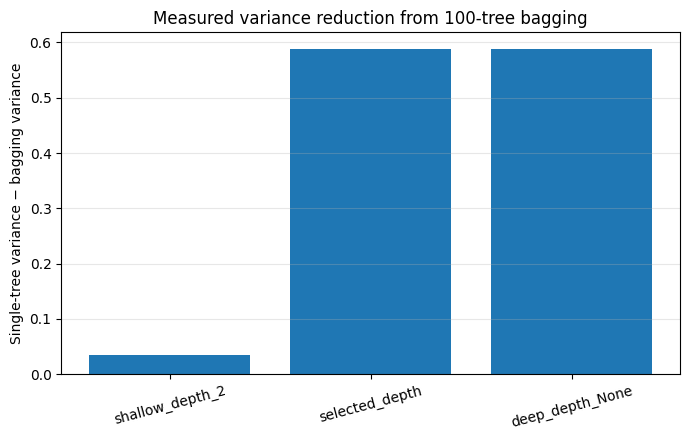

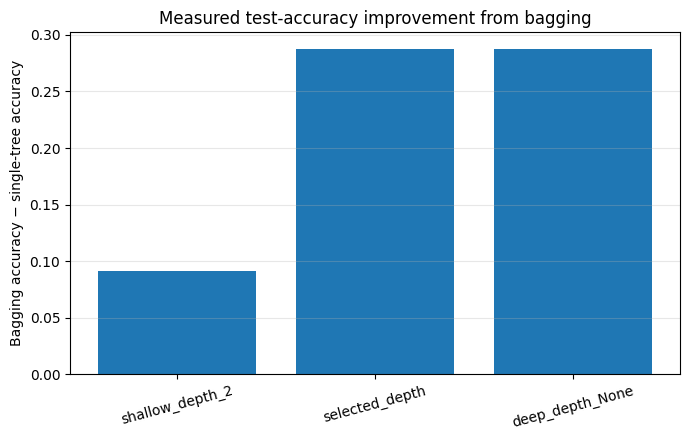

In [10]:
q3c_rows = []
for label, depth in DEPTH_COMPARISON:
    sub = q3b_df[q3b_df["depth_setting"] == label].set_index("model")
    q3c_rows.append({
        "depth_setting": label,
        "depth": str(depth),
        "single_tree_bias_squared": float(sub.loc["Single tree", "bias_squared"]),
        "bagging_bias_squared": float(sub.loc["Bagging-100", "bias_squared"]),
        "single_tree_variance": float(sub.loc["Single tree", "variance"]),
        "bagging_variance": float(sub.loc["Bagging-100", "variance"]),
        "variance_reduction": float(sub.loc["Single tree", "variance"] - sub.loc["Bagging-100", "variance"]),
        "single_tree_mean_test_accuracy": float(sub.loc["Single tree", "mean_test_accuracy"]),
        "bagging_mean_test_accuracy": float(sub.loc["Bagging-100", "mean_test_accuracy"]),
        "accuracy_improvement": float(sub.loc["Bagging-100", "mean_test_accuracy"] -
                                       sub.loc["Single tree", "mean_test_accuracy"])
    })
q3c_df = pd.DataFrame(q3c_rows)
display(q3c_df)
q3c_df.to_csv(os.path.join(OUT_DIR, "q3c_bagging_improvement_by_depth.csv"), index=False)

plt.figure(figsize=(7, 4.5))
plt.bar(q3c_df["depth_setting"], q3c_df["variance_reduction"])
plt.ylabel("Single-tree variance − bagging variance")
plt.title("Measured variance reduction from 100-tree bagging")
plt.xticks(rotation=15)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "q3c_variance_reduction_by_depth.png"), dpi=160)
plt.show()

plt.figure(figsize=(7, 4.5))
plt.bar(q3c_df["depth_setting"], q3c_df["accuracy_improvement"])
plt.ylabel("Bagging accuracy − single-tree accuracy")
plt.title("Measured test-accuracy improvement from bagging")
plt.xticks(rotation=15)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "q3c_accuracy_improvement_by_depth.png"), dpi=160)
plt.show()

## 8. Q3(d): final comparison table and clean/masked sensitivity

Create the final table for the selected single tree, selected bagging model, and selected boosting model with clean test accuracy, masked test accuracy, bias squared, and variance. Bias/variance are measured on the fixed clean test set across 30 refits. Clean/masked accuracy is measured using the frozen models fitted on the original clean training set.

In [11]:
# Clean and masked performance for the frozen models fitted on original training data.
def bagging_predict(X_eval, models):
    vec = class_vectors_from_bagging(models, X_eval, classes)
    return classes[np.argmax(vec, axis=1)], vec.max(axis=1)

clean_rows = []
# Single tree
st_clean = single_tree.predict(X_test)
st_mask = single_tree.predict(X_test_masked)
clean_rows.append({
    "model": "Single tree",
    "clean_test_accuracy": accuracy_score(y_test, st_clean),
    "masked_test_accuracy": accuracy_score(y_test, st_mask)
})
# Bagging
bg_clean, bg_clean_conf = bagging_predict(X_test, bag_models_all)
bg_mask, bg_mask_conf = bagging_predict(X_test_masked, bag_models_all)
clean_rows.append({
    "model": f"Bagging B={FINAL_B}",
    "clean_test_accuracy": accuracy_score(y_test, bg_clean),
    "masked_test_accuracy": accuracy_score(y_test, bg_mask)
})
# Boosting
bo_clean = boost_model.predict(X_test)
bo_mask = boost_model.predict(X_test_masked)
clean_rows.append({
    "model": f"Boosting depth={BOOST_DEPTH}, rounds={len(boost_model.estimators_)}",
    "clean_test_accuracy": accuracy_score(y_test, bo_clean),
    "masked_test_accuracy": accuracy_score(y_test, bo_mask)
})
clean_mask_df = pd.DataFrame(clean_rows)

bias_variance_map = {
    "Single tree": q3a_df.set_index("model").loc["Single tree"],
    "Bagging": q3a_df.set_index("model").loc["Bagging"],
    "Boosting": q3a_df.set_index("model").loc["Boosting"]
}
final_rows = []
for _, row in clean_mask_df.iterrows():
    if row["model"] == "Single tree":
        bv = bias_variance_map["Single tree"]
    elif row["model"].startswith("Bagging"):
        bv = bias_variance_map["Bagging"]
    else:
        bv = bias_variance_map["Boosting"]
    final_rows.append({
        "model": row["model"],
        "clean_test_accuracy": float(row["clean_test_accuracy"]),
        "masked_test_accuracy": float(row["masked_test_accuracy"]),
        "bias_squared": float(bv["bias_squared"]),
        "variance": float(bv["variance"])
    })
final_table = pd.DataFrame(final_rows)
display(final_table)
final_table.to_csv(os.path.join(OUT_DIR, "q3d_final_comparison_table.csv"), index=False)

# Summarise masked accuracy drop.
final_table["masked_accuracy_drop"] = final_table["clean_test_accuracy"] - final_table["masked_test_accuracy"]
display(final_table[["model", "masked_accuracy_drop"]])
final_table.to_csv(os.path.join(OUT_DIR, "q3d_final_comparison_table_with_mask_drop.csv"), index=False)

,model,clean_test_accuracy,masked_test_accuracy,bias_squared,variance
0,Single tree,0.6625,0.2875,0.353000,0.617833
1,Bagging B=200,0.9125,0.7250,0.491176,0.018820
2,"Boosting depth=4, rounds=100",0.4750,0.4500,0.885714,0.016619


,model,masked_accuracy_drop
0,Single tree,0.3750
1,Bagging B=200,0.1875
2,"Boosting depth=4, rounds=100",0.0250


## 9. Save a compact summary and output inventory

In [12]:
summary = {
    "roll_number": ROLL_NUMBER,
    "seed": SEED,
    "fixed_split": {
        "train": int(len(train_idx)), "validation": int(len(val_idx)), "test": int(len(test_idx)),
        "split_file": os.path.basename(split_path)
    },
    "frozen_settings": {
        "tree_depth": TREE_DEPTH if TREE_DEPTH is not None else "None",
        "tree_min_samples_leaf": TREE_MIN_LEAF,
        "final_bagging_B": FINAL_B,
        "boosting_depth": BOOST_DEPTH,
        "boosting_requested_rounds": BOOST_ROUNDS,
        "boosting_actual_rounds": len(boost_model.estimators_)
    },
    "q3a": q3a_rows,
    "q3b": q3b_rows,
    "q3c": q3c_rows,
    "q3d": final_rows
}
with open(os.path.join(OUT_DIR, "q3_results_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=lambda x: float(x) if isinstance(x, (np.floating,)) else int(x) if isinstance(x, (np.integer,)) else str(x))

print("Saved outputs:")
for filename in sorted(os.listdir(OUT_DIR)):
    print(" -", filename)

Saved outputs:
 - q3_results_summary.json
 - q3a_bias_variance_selected_models.csv
 - q3a_test_accuracy_by_refit.csv
 - q3b_depth_bias_variance.csv
 - q3b_depth_test_accuracy_by_refit.csv
 - q3b_leaf_statistics.csv
 - q3c_accuracy_improvement_by_depth.png
 - q3c_bagging_improvement_by_depth.csv
 - q3c_variance_reduction_by_depth.png
 - q3d_final_comparison_table.csv
 - q3d_final_comparison_table_with_mask_drop.csv


## 10. Reporting checklist for Q3

- **Q3(a):** selected single tree, final bagging, and selected boosting bias squared and variance; mean and standard deviation of test accuracy across 30 refits.
- **Q3(b):** shallow, selected, and deep tree settings; matching 100-tree bagging ensembles; measured bias, variance, test accuracy, and tree leaf statistics.
- **Q3(c):** measured accuracy improvement and variance reduction for each depth. Discuss whether the deepest tree gave the largest gain based on these results and your Q1 disagreement/leaf occupancy measurements.
- **Q3(d):** final table with clean test accuracy, masked test accuracy, bias squared, and variance; explain stability, masked-region sensitivity, and why lower variance does not automatically imply higher accuracy.
- **Reproducibility:** keep the notebook, fixed split, CSV tables, plots, and JSON summary together.

The resampling procedure is computationally expensive: Q3(b) fits 100-tree ensembles for three depth settings over 30 repetitions. If Colab times out, run the earlier sections first and resume from the interrupted cell; do not change the split or the 30 repetitions without documenting it.